# ML: Predictive Maintenance

**Data:** The AI4I 2020 Predictive Maintenance Dataset is a synthetic dataset that reflects real predictive maintenance data encountered in industry. (https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

**Task:** Predict whether a machine will fail (`Machine failure`).


**How ​​to work with the notebook:**
- Install the necessary libraries: `pip install -r req.txt`
- Each stage begins with an introduction to the specific problem or topic and concludes with 2 or 3 tasks to complete and questions to answer.
- Write new code to complete the tasks; do not modify the existing code.
- Enter your answers to the questions in the text cells where it says `Your answer:`. Refer to **your own results**.
- Stuck? Ask the instructor for help, or move on to the next task. Each stage is relatively independent.
- You will receive **1 point** for the answer to each question or task. You will receive **2 points** for the answer to the final question. You can earn a total of **15 points**.
- **Laboratory grade = total_points / 3**.
- Submit the entire notebook at the end of the session!!!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, f1_score
from ucimlrepo import fetch_ucirepo
import seaborn as sns

SEED = 42
ds = fetch_ucirepo(id=601)
df = pd.concat([ds.data.features, ds.data.targets], axis=1)

print(df.shape)
df.head()

(10000, 12)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Data Exploration – EDA

Exploratory Data Analysis: examine the data and check if it requires cleaning. Look closely at the distribution of the target class.

Additionally, a "pseudo-model" is created in this section; despite its high accuracy, it is completely useless.

In [2]:
df.isnull().sum()


Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
Machine failure        0
TWF                    0
HDF                    0
PWF                    0
OSF                    0
RNF                    0
dtype: int64

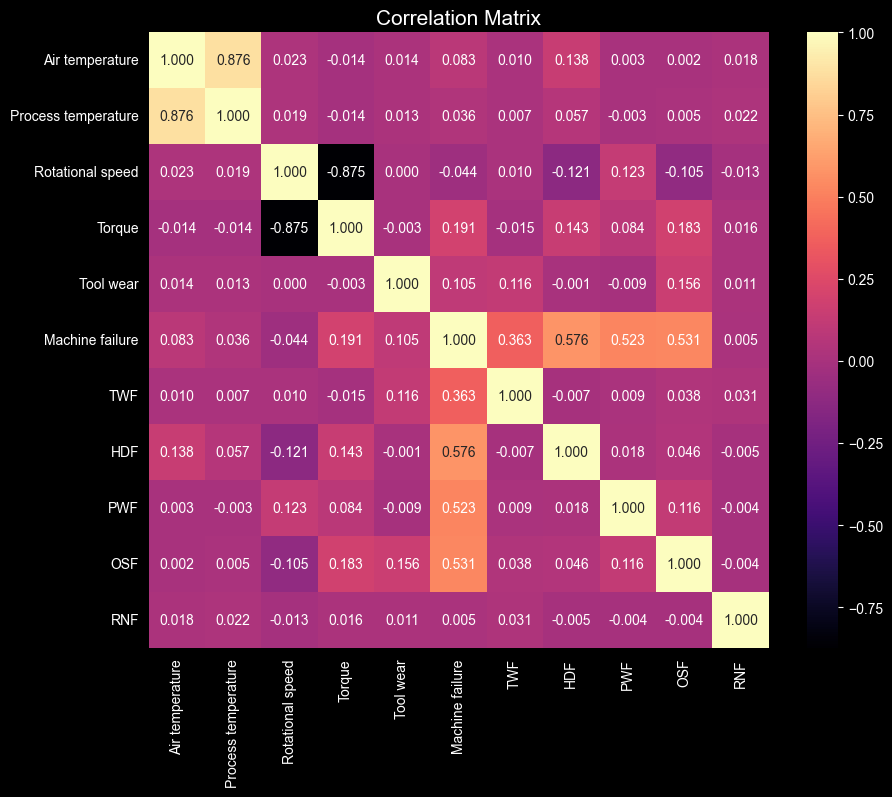

In [3]:
fig, ax= plt.subplots(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), cmap='magma', annot=True, fmt='0.3f',ax=ax)
ax.set_title('Correlation Matrix', fontsize=15);

In [4]:
df.describe()

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


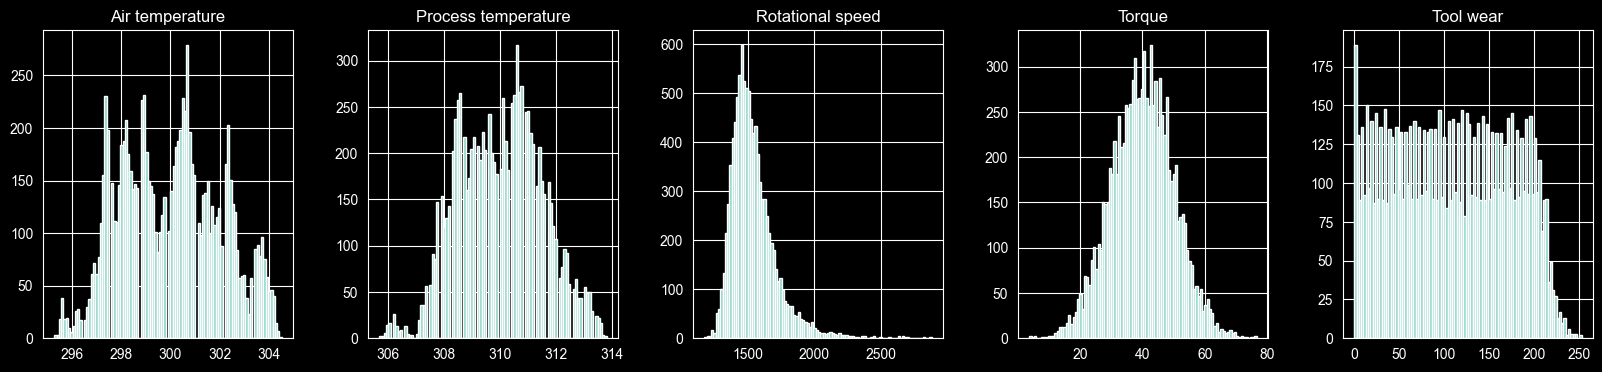

In [5]:
df.iloc[:, :6].hist(bins=100, figsize=(20,4), layout=(1, 5))
plt.show()

In [6]:
print(df["Machine failure"].value_counts())
print(f"Failure rate: {df['Machine failure'].mean():.1%}")

baseline_acc = 1 - df["Machine failure"].mean()
print(f"Pseudo-model (always return: no failure): {baseline_acc:.1%}")

Machine failure
0    9661
1     339
Name: count, dtype: int64
Failure rate: 3.4%
Pseudo-model (always return: no failure): 96.6%


## Step 1. Creating a simple, functional model

A typical pipeline consists of: **feature and label selection, train/test splitting, training, prediction, and model evaluation.**
When dealing with a rare positive class (representing a few percent of the data), the split must preserve the class proportions in both sets. A purely random split could result in a training set containing virtually no data on failures (**stratify**)
The columns `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` represent failure types that we are ignoring for now (we are removing these columns from the dataset).

In [9]:
print(df.head())

  Type  Air temperature  Process temperature  Rotational speed  Torque  \
0    M            298.1                308.6              1551    42.8   
1    L            298.2                308.7              1408    46.3   
2    L            298.1                308.5              1498    49.4   
3    L            298.2                308.6              1433    39.5   
4    L            298.2                308.7              1408    40.0   

   Tool wear  Machine failure  TWF  HDF  PWF  OSF  RNF  
0          0                0    0    0    0    0    0  
1          3                0    0    0    0    0    0  
2          5                0    0    0    0    0    0  
3          7                0    0    0    0    0    0  
4          9                0    0    0    0    0    0  


In [7]:
y = df["Machine failure"]
X = df.drop(columns=["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF", "UDI", "Product ID"], errors="ignore")

X = pd.get_dummies(X, columns=["Type"], drop_first=True)  # kodowanie typu produktu (L/M/H)
X.head()

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,False,True
1,298.2,308.7,1408,46.3,3,True,False
2,298.1,308.5,1498,49.4,5,True,False
3,298.2,308.6,1433,39.5,7,True,False
4,298.2,308.7,1408,40.0,9,True,False


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

In [12]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

,steps,"[('standardscaler', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [13]:
y_pred = model.predict(X_test)

print(f"Accuracy:           {accuracy_score(y_test, y_pred):.3f}")
print(f"F score:            {f1_score(y_test, y_pred):.3f}")
print(f"Recall:             {recall_score(y_test, y_pred):.3f}")
print(f"Accuracy baseline:  {accuracy_score(y_test, np.zeros(len(y_test))):.3f}")

Accuracy:           0.968
F score:            0.177
Recall:             0.103
Accuracy baseline:  0.966


## Stage 2. Comparing classifiers – perhaps another one will perform better

There are many different classifiers suitable for various situations. For now, we are focusing on the three most fundamental ones: **Logistic Regression** seeks a linear boundary, a **Decision Tree** splits data based on simple rules, and **Random Forest** averages the results of multiple trees.

When dealing with a rare positive class, so we evaluate the model using **recall** and **F1** rather than accuracy!

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.neighbors import KNeighborsClassifier
import time

def models_compare(models, X_train, X_test, y_train, y_test):
    rows = {}

    for name, m in models.items():
        start = time.time()
        m.fit(X_train, y_train)
        t = time.time() - start
        y_hat = m.predict(X_test)
        rows[name] = {
            "accuracy": accuracy_score(y_test, y_hat),
            "precision": precision_score(y_test, y_hat, zero_division=0),
            "recall": recall_score(y_test, y_hat),
            "F1": f1_score(y_test, y_hat),
            "time [s]": t,
        }
    return pd.DataFrame(rows).T.round(3)

In [25]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED),
}
results = models_compare(models, X_train, X_test, y_train, y_test)
results


,accuracy,precision,recall,F1,time [s]
Logistic Regression,0.968,0.636,0.103,0.177,0.008
Decision Tree,0.978,0.682,0.662,0.672,0.017
Random Forest,0.982,0.878,0.529,0.661,0.334


In [17]:
best_recall = results["recall"].idxmax()
best_accuracy = results["accuracy"].idxmax()
best_F1 = results["F1"].idxmax()
print("Best recall:  ", best_recall)
print("Best accuracy:", best_accuracy)
print("Best F1:      ", best_F1)

Best recall:   Decision Tree
Best accuracy: Random Forest
Best F1:       Decision Tree


**Tasks**
1. Set `class_weight="balanced"` for the logistic regression and random forest models. How did recall and precision change?
2. Add `KNeighborsClassifier` to the dictionary (remember to scale the features) and explain why scaling is important for this algorithm.
3. Test the KNN model for different numbers of neighbors. How does the number of neighbors affect accuracy, recall and F1?

Your answers:
1. Wyniki dla Regresji logistycznej spadły, natomiast dla lasów lostowych wzrosły, prawdopodobnie z powodu małej ilości danych
na temat awarri systemu. Regresja logistyczna przez swoją "zero jedynkowość" mimała mniej danych do dostosowywanie się małej ilosci awarii.
Drzewa losowe przez uśrednianie dały lepsze wyniki.
2. Scalowanie przedłużyło czas brak różnic i brak wniosków
3. Dla zbyt dużej ilości sąsiadów precyzja spada do 0, poniewaz w zbiorze danych jest małą ilość awarii, więc KNNN ma najwięcej sąsiadów z wartośćią 0 nieporoównywalnie do sąsiadów z wartośćią 1

In [26]:
results

,accuracy,precision,recall,F1,time [s]
Logistic Regression,0.968,0.636,0.103,0.177,0.008
Decision Tree,0.978,0.682,0.662,0.672,0.017
Random Forest,0.982,0.878,0.529,0.661,0.334


In [37]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, class_weight="balanced"),
    "KNeighborsClassifier": KNeighborsClassifier()

}
a = models_compare(models, X_train, X_test, y_train, y_test)

a


,accuracy,precision,recall,F1,time [s]
Logistic Regression,0.824,0.142,0.824,0.242,0.009
Decision Tree,0.978,0.682,0.662,0.672,0.017
Random Forest,0.981,0.941,0.471,0.627,0.300
KNeighborsClassifier,0.970,0.700,0.206,0.318,0.005
KNeighborsClassifierNonscaled,0.970,0.700,0.206,0.318,0.005


In [38]:
best_recall = a["recall"].idxmax()
best_accuracy = a["accuracy"].idxmax()
best_F1 = a["F1"].idxmax()
print("Best recall:  ", best_recall)
print("Best accuracy:", best_accuracy)
print("Best F1:      ", best_F1)

Best recall:   Logistic Regression
Best accuracy: Random Forest
Best F1:       Decision Tree


zad 2

In [40]:
def models_compare2(models, X_train, X_test, y_train, y_test):
    rows = {}

    for name, m in models.items():
        start = time.time()
        if(models == "KNeighborsClassifier"):
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.fit_transform(X_test)
        m.fit(X_train, y_train)
        t = time.time() - start
        y_hat = m.predict(X_test)
        rows[name] = {
            "accuracy": accuracy_score(y_test, y_hat),
            "precision": precision_score(y_test, y_hat, zero_division=0),
            "recall": recall_score(y_test, y_hat),
            "F1": f1_score(y_test, y_hat),
            "time [s]": t,
        }
    return pd.DataFrame(rows).T.round(3)

In [41]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, class_weight="balanced"),
    "KNeighborsClassifier": KNeighborsClassifier(),
    "KNeighborsClassifierNNonScaled": KNeighborsClassifier()
}
a = models_compare2(models, X_train, X_test, y_train, y_test)

a


,accuracy,precision,recall,F1,time [s]
Logistic Regression,0.824,0.142,0.824,0.242,0.011
Decision Tree,0.978,0.682,0.662,0.672,0.017
Random Forest,0.981,0.941,0.471,0.627,0.313
KNeighborsClassifier,0.970,0.700,0.206,0.318,0.006
KNeighborsClassifierNNonScaled,0.970,0.700,0.206,0.318,0.005


zad 3

In [44]:
models = {
    "KNeighborsClassifier1": KNeighborsClassifier(n_neighbors=1),
    "KNeighborsClassifier5": KNeighborsClassifier(n_neighbors=5),
    "KNeighborsClassifier20": KNeighborsClassifier(n_neighbors=20),
    "KNeighborsClassifier100": KNeighborsClassifier(n_neighbors=100),
    "KNeighborsClassifier150": KNeighborsClassifier(n_neighbors=1000),
}
a = models_compare2(models, X_train, X_test, y_train, y_test)

a

,accuracy,precision,recall,F1,time [s]
KNeighborsClassifier1,0.962,0.418,0.338,0.374,0.007
KNeighborsClassifier5,0.970,0.700,0.206,0.318,0.005
KNeighborsClassifier20,0.970,1.000,0.132,0.234,0.005
KNeighborsClassifier100,0.966,0.000,0.000,0.000,0.006
KNeighborsClassifier150,0.966,0.000,0.000,0.000,0.005


## Stage 3. Overfitting, illustrated by tree depth
A model overfits when, instead of learning general patterns, it memorizes the specific details and noise of the training set. Consequently, performance on the training set improves, while performance on the test set stabilizes or declines.

To demonstrate this, we will increase the complexity of our decision tree model using the `max_depth` parameter.
There are only a few hundred failure cases in the training set, so a deep tree will quickly memorize them. This effect is most clearly visible with the **F1** metric.

In [52]:
def plot_F1_score(depths, f1_train, f1_test):
    plt.figure(figsize=(7, 4))
    plt.plot(depths, f1_train, marker="o", label="train")
    plt.plot(depths, f1_test, marker="o", label="test")
    plt.xlabel("max_depth")
    plt.ylabel("F1 score")
    plt.title("The impact of tree complexity on the F1 score")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

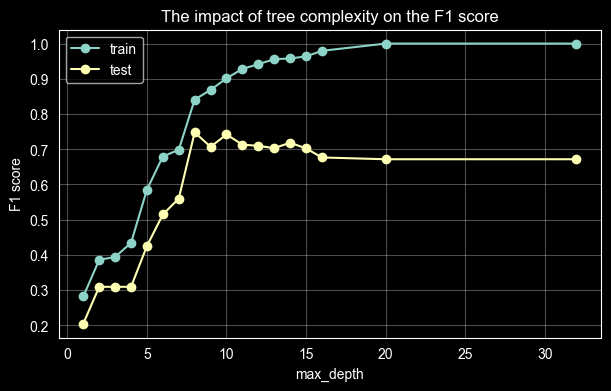

In [46]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 20, 32]
f1_train, f1_test = [], []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    tree.fit(X_train, y_train)
    f1_train.append(f1_score(y_train, tree.predict(X_train)))
    f1_test.append(f1_score(y_test, tree.predict(X_test)))

plot_F1_score(depths, f1_train, f1_test)

In [47]:
optimal_tree_depth = depths[int(np.argmax(f1_test))]
print(f"Optimal tree depth based on F1 score = {optimal_tree_depth}")

Optimal tree depth based on F1 score = 8


1. Repeat the experiment for the random forest, varying `min_samples_leaf` from 1 to 20. Does the forest overfit in the same way as a single tree?
2. Use `cross_val_score` with `cv=5` on the training set to select the depth without looking at the test set. Is the selected depth the same?

Your answer:
1. Tym wiecej lisci tym slabszy wynik. Overfitting

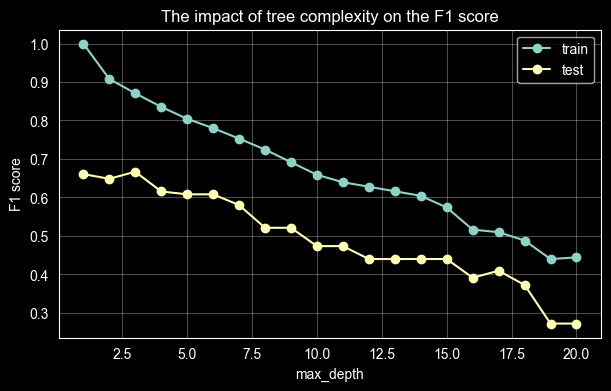

In [54]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 20, 32]
leaf = list(range(1,21))


f1_train, f1_test = [], []

for d in leaf:
    tree = RandomForestClassifier(min_samples_leaf=d, random_state=SEED)
    tree.fit(X_train, y_train)
    f1_train.append(f1_score(y_train, tree.predict(X_train)))
    f1_test.append(f1_score(y_test, tree.predict(X_test)))

plot_F1_score(leaf, f1_train, f1_test)


zad 2

In [57]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
#2. Use `cross_val_score` with `cv=5` on the training set to select the depth without looking at the test set. Is the selected depth the same?
svm_classifier = SVC(kernel='linear')
cross_val_results = cross_val_score(svm_classifier, X_train, y_train, cv=5)

## Stage 4. Model evaluation pitfalls and confusion matrices

**Pitfall 1: Evaluating the model based solely on accuracy.** A model that never reports a failure achieves an accuracy of approximately 96.5% yet is useless. Therefore, evaluation should take into account the **confusion matrix** and metrics for the positive class:
- **precision**: the proportion of reported failures that were actual failures,
- **recall**: the proportion of actual failures detected by the model,
- **F1**: the harmonic mean of the two.

**Pitfall 2: Data leakage.** The model receives information it should not have access to (e.g., the failure type). This improves the model's results, but in practice, the model is useless.

In [ ]:
# Models for comparison: random forest and pseudo-model
rf = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_pred_base = np.zeros(len(y_test), dtype=int)
f1_rf = f1_score(y_test, y_pred_rf)

In [ ]:
for name, y_hat in [("baseline", y_pred_base), ("random forest", y_pred_rf)]:
    acc = accuracy_score(y_test, y_hat)
    prec = precision_score(y_test, y_hat, zero_division=0)
    rec = recall_score(y_test, y_hat)
    f1 = f1_score(y_test, y_hat)
    print(f"{name:14s} accuracy={acc:.3f}  precision={prec:.3f}  recall={rec:.3f}  F1={f1:.3f}")

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_base, ax=ax[0], colorbar=False, cmap="Reds")
ax[0].set_title("Baseline")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, ax=ax[1], colorbar=False, cmap="Greens")
ax[1].set_title("Random forest")
plt.show()

In [ ]:
tnb, fpb, fnb, tpb = confusion_matrix(y_test, y_pred_base).ravel()
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_rf).ravel()
print("                   Base  Random Forest")
print(f"Detected failures:  {tpb}        {tp}")
print(f"Missed failures:    {fnb}       {fn}")
print(f"False alarms:       {fpb}        {fp}")

### Data leakage

So far, we have omitted the `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` columns. These represent **failure types** (tool wear, heat dissipation, power, overload, random). Let's add them to the features and see what happens.

In [ ]:
data_leak = ["TWF", "HDF", "PWF", "OSF", "RNF"]
X_leak = pd.concat([X, df[data_leak]], axis=1)

In [ ]:
Xl_train, Xl_test, yl_train, yl_test = train_test_split(X_leak, y, test_size=0.2, stratify=y, random_state=SEED)
rf_leak = RandomForestClassifier(n_estimators=100, random_state=SEED)

In [ ]:
rf_leak.fit(Xl_train, yl_train)
f1_leak = f1_score(yl_test, rf_leak.predict(Xl_test))
print(f"F1 without failure mode columns: {f1_rf:.3f}")
print(f"F1 with failure type columns:    {f1_leak:.3f}")

**Tasks:**
1. Check how the leakage affects other model parameters.
2. Examine `feature_importances_` in `rf_leak`. Which features dominate?
3. Demonstrate leakage caused by preprocessing: fit a `StandardScaler` on the **entire** dataset before the split and compare the result with the correct approach (scaler fitted only on the training set). Why is the difference small here, yet the method is still flawed?

Your answer:

## Stage 5. ROC curve and decision threshold

A classification model typically returns the **probability** of a failure, and the `predict` method converts this into a decision using a threshold of **0.5**. We can adjust this threshold as needed:
- **lower threshold**: more reported failures, higher recall, lower precision (more false alarms),
- **higher threshold**: fewer reports, higher precision, lower recall (more missed failures).

The **ROC curve** illustrates how the rate of detected failures (TPR) and the false alarm rate (FPR) change across all possible thresholds.

**AUC** represents the area under the curve: 0.5 indicates random guessing, while 1.0 represents a perfect model.

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

y = df["Machine failure"]
X = df.drop(columns=["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF", "UDI", "Product ID"], errors="ignore")
X = pd.get_dummies(X, columns=["Type"], drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

# Two models for comparing ROC curves - LogisticRegression and RandomForestClassifier
model_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
model_rf = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(X_train, y_train)

In [ ]:
p_lr = model_lr.predict_proba(X_test)[:, 1]
p_rf = model_rf.predict_proba(X_test)[:, 1]

In [ ]:
auc_lr = roc_auc_score(y_test, p_lr)
auc_rf = roc_auc_score(y_test, p_rf)
print(f"AUC Logistic Regression: {auc_lr:.3f}")
print(f"AUC Random Forest:       {auc_rf:.3f}")

In [ ]:
plt.figure(figsize=(5.5, 5))
for name, p, auc in [("Logistic Regression", p_lr, auc_lr), ("Random forest", p_rf, auc_rf)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="random classifier")
plt.xlabel("FPR (false alarm rate)")
plt.ylabel("TPR (true positive rate)")
plt.title("ROC curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Threshold Selection

Let's examine how precision and recall for the random forest change as we shift the threshold.

In [ ]:
tres = np.round(np.arange(0.05, 0.96, 0.05), 2)
table = []
for t in tres:
    y_hat = (p_rf >= t).astype(int)
    table.append((t, precision_score(y_test, y_hat, zero_division=0), recall_score(y_test, y_hat)))

In [ ]:
df_tres = pd.DataFrame(table, columns=["Threshold", "Precision", "Recall"]).round(3)
df_tres

In [ ]:
threshold = df_tres[df_tres["Recall"] >= 0.8]["Threshold"].max()
precision_tres = precision_score(y_test, (p_rf >= threshold).astype(int), zero_division=0)
print(f"Selected threshold: {threshold}, precision at this threshold: {precision_tres:.3f}")

**Tasks:**
1. Plot the precision-recall curve (`precision_recall_curve`) and calculate the `average_precision_score`. Is it more informative than the ROC curve? Justify your answer.
2. We selected the threshold using the test set. How else could this be done? Hint: use `cross_val_predict` with `method="predict_proba"` on the training set. Which of the three resulting thresholds do you consider the best, and why?

Your answer:

## Stage 6. Feature Engineering

**Feature engineering** involves creating new columns from existing ones to better capture the mechanism we aim to predict.

In this dataset, failures have physical causes, so we can leverage domain knowledge:
- **temperature difference** (process minus air): a small difference indicates poor heat dissipation,
- **power** (torque times angular velocity): excessively low or high power indicates a drive system issue. Convert speed from rpm to rad/s by multiplying by 2π/60.

In [ ]:
def model_evaluate(X_tr, X_te, Y_tr, Y_te):
    """Trains a random forest on X_tr and returns F1, recall, and AUC on X_te (threshold 0.5).."""
    m = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(X_tr, Y_tr)
    p = m.predict_proba(X_te)[:, 1]
    y_hat = (p >= 0.5).astype(int)
    return {"F1": f1_score(Y_te, y_hat), "recall": recall_score(Y_te, y_hat), "AUC": roc_auc_score(Y_te, p)}

results = model_evaluate(X_train, X_test, y_train, y_test)
print("Result without new features:", {k: round(v, 3) for k, v in results.items()})

In [ ]:
def add_features(X_df):
    X_new = X_df.copy()
    X_new["temp_diff"] = X_new["Process temperature"] - X_new["Air temperature"]
    X_new["power"] = X_new["Torque"] * X_new["Rotational speed"] * 2 * np.pi / 60
    return X_new

In [ ]:
X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)
results_new_features = model_evaluate(X_train_fe, X_test_fe, y_train, y_test)
pd.DataFrame({"before": results, "after": results_new_features}).round(3)

**Tasks:**
1. Add a third feature, `Tool wear * Torque` (tool wear times torque), and check if the result improves.
2. Propose another fourth feature. How does it affect the result?
3. Test each feature individually (only `roznica_temp`, only `moc`). Which of the 4 new features has the greatest impact on the model?

Your answer:

## Final Question

Select the model and decision threshold you would implement in the factory. Justify your choice by **referring to your results** (recall, precision, AUC, number of missed failures and false alarms) and the costs associated with both types of errors.

Your answer:


**Before submitting the notebook:** check that all cells execute without errors.